<a href="https://colab.research.google.com/github/aadeshbhamare/DataScience-Week2---WeIntern-Project/blob/main/notebooks/Task_01_Data_Cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
BASE_URL = "https://raw.githubusercontent.com/aadeshbhamare/DataScience-Week2---WeIntern-Project/main/data/raw/"

train = pd.read_csv(BASE_URL + "train.csv")
test = pd.read_csv(BASE_URL + "test.csv")
store = pd.read_csv(BASE_URL + "store.csv")
sample_submission = pd.read_csv(BASE_URL + "sample_submission.csv")

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [ ]:
datasets_raw = {
    "Train": train,
    "Test": test,
    "Store": store,
    "Sample Submission": sample_submission
}

for name, df in datasets_raw.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

Train: 1,017,209 rows × 9 columns
Test: 41,088 rows × 8 columns
Store: 1,115 rows × 10 columns
Sample Submission: 41,088 rows × 2 columns


In [ ]:
# Keep source data unchanged for reproducibility and before/after comparisons.
train_raw = train.copy(deep=True)
test_raw = test.copy(deep=True)
store_raw = store.copy(deep=True)
sample_submission_raw = sample_submission.copy(deep=True)

train_clean = train.copy(deep=True)
test_clean = test.copy(deep=True)
store_clean = store.copy(deep=True)

print("Raw snapshots and independent cleaning copies created.")

Raw snapshots and independent cleaning copies created.


In [ ]:
overview_rows = []
for name, df in datasets_raw.items():
    overview_rows.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Duplicate Rows": int(df.duplicated().sum()),
        "Missing Cells": int(df.isna().sum().sum())
    })

dataset_overview = pd.DataFrame(overview_rows)
display(dataset_overview)

for name, df in datasets_raw.items():
    print("\\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)
    print("Columns:", df.columns.tolist())
    display(df.head())

,Dataset,Rows,Columns,Duplicate Rows,Missing Cells
0,Train,1017209,9,0,0
1,Test,41088,8,0,11
2,Store,1115,10,0,2343
3,Sample Submission,41088,2,0,0


\n=================================================================
TRAIN
Columns: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


\n=================================================================
TEST
Columns: ['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.00,1,0,0
1,2,3,4,2015-09-17,1.00,1,0,0
2,3,7,4,2015-09-17,1.00,1,0,0
3,4,8,4,2015-09-17,1.00,1,0,0
4,5,9,4,2015-09-17,1.00,1,0,0


\n=================================================================
STORE
Columns: ['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN
1,2,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN
4,5,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN


\n=================================================================
SAMPLE SUBMISSION
Columns: ['Id', 'Sales']


,Id,Sales
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


In [ ]:
for name, df in datasets_raw.items():
    print("\n" + "=" * 65)
    print(f"{name.upper()} — DATA TYPE PROFILE")
    print("=" * 65)
    profile = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Non-Null Count": df.notna().sum(),
        "Unique Values": df.nunique(dropna=True)
    })
    display(profile)


TRAIN — DATA TYPE PROFILE


,Data Type,Non-Null Count,Unique Values
Store,int64,1017209,1115
DayOfWeek,int64,1017209,7
Date,object,1017209,942
Sales,int64,1017209,21734
Customers,int64,1017209,4086
Open,int64,1017209,2
Promo,int64,1017209,2
StateHoliday,object,1017209,5
SchoolHoliday,int64,1017209,2



TEST — DATA TYPE PROFILE


,Data Type,Non-Null Count,Unique Values
Id,int64,41088,41088
Store,int64,41088,856
DayOfWeek,int64,41088,7
Date,object,41088,48
Open,float64,41077,2
Promo,int64,41088,2
StateHoliday,object,41088,2
SchoolHoliday,int64,41088,2



STORE — DATA TYPE PROFILE


,Data Type,Non-Null Count,Unique Values
Store,int64,1115,1115
StoreType,object,1115,4
Assortment,object,1115,3
CompetitionDistance,float64,1112,654
CompetitionOpenSinceMonth,float64,761,12
CompetitionOpenSinceYear,float64,761,23
Promo2,int64,1115,2
Promo2SinceWeek,float64,571,24
Promo2SinceYear,float64,571,7
PromoInterval,object,571,3



SAMPLE SUBMISSION — DATA TYPE PROFILE


,Data Type,Non-Null Count,Unique Values
Id,int64,41088,41088
Sales,int64,41088,1



MISSING VALUES ANALYSIS - Train


,Missing Count,Missing Percentage (%)


No missing values found.

MISSING VALUES ANALYSIS - Test


,Missing Count,Missing Percentage (%)
Open,11,0.03



MISSING VALUES ANALYSIS - Store


,Missing Count,Missing Percentage (%)
CompetitionDistance,3,0.27
CompetitionOpenSinceMonth,354,31.75
CompetitionOpenSinceYear,354,31.75
Promo2SinceWeek,544,48.79
Promo2SinceYear,544,48.79
PromoInterval,544,48.79



MISSING VALUES ANALYSIS - Sample Submission


,Missing Count,Missing Percentage (%)


No missing values found.

OVERALL MISSING VALUES SUMMARY


,Dataset,Column,Missing Count,Missing Percentage (%)
24,Store,Promo2SinceWeek,544,48.79
25,Store,Promo2SinceYear,544,48.79
26,Store,PromoInterval,544,48.79
21,Store,CompetitionOpenSinceMonth,354,31.75
22,Store,CompetitionOpenSinceYear,354,31.75
20,Store,CompetitionDistance,3,0.27
13,Test,Open,11,0.03


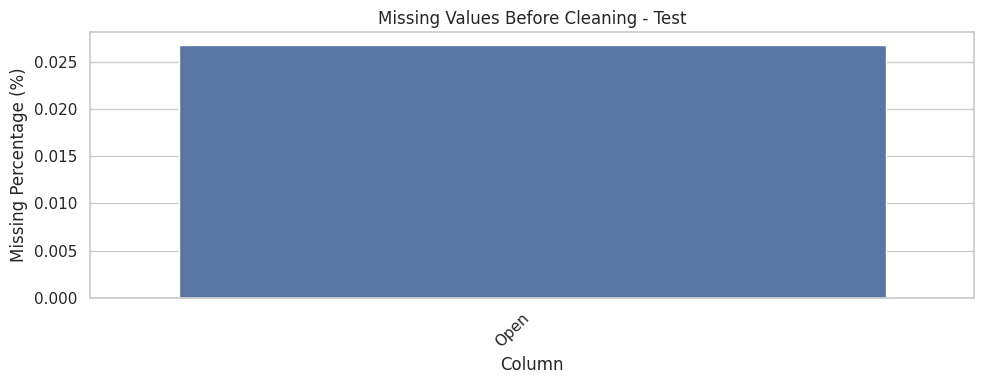

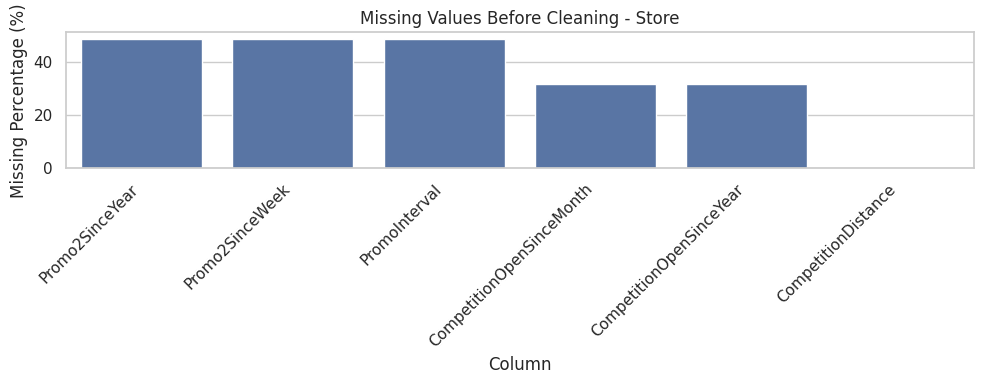

In [ ]:
# ============================================================
# MISSING VALUES ANALYSIS BEFORE CLEANING
# ============================================================

missing_rows = []

# 1. Check Missing Values in All Datasets
for name, df in datasets_raw.items():

    print("\n" + "=" * 60)
    print(f"MISSING VALUES ANALYSIS - {name}")
    print("=" * 60)

    missing_count = df.isnull().sum()
    missing_percentage = (missing_count / len(df)) * 100

    # Create Missing Values Report
    missing_report = pd.DataFrame({
        "Missing Count": missing_count,
        "Missing Percentage (%)": missing_percentage.round(2)
    })

    display(missing_report[missing_report["Missing Count"] > 0])

    if missing_count.sum() == 0:
        print("No missing values found.")

    # Store Missing Values Details
    for column in df.columns:

        count = int(df[column].isna().sum())

        missing_rows.append({
            "Dataset": name,
            "Column": column,
            "Missing Count": count,
            "Missing Percentage (%)": round(
                count / len(df) * 100, 2
            )
        })


# 2. Create Overall Missing Values Summary
missing_before_df = pd.DataFrame(missing_rows)

print("\n" + "=" * 60)
print("OVERALL MISSING VALUES SUMMARY")
print("=" * 60)

display(
    missing_before_df[
        missing_before_df["Missing Count"] > 0
    ].sort_values(
        ["Dataset", "Missing Count"],
        ascending=[True, False]
    )
)


# 3. Visualize Missing Values for Each Dataset
for name, df in datasets_raw.items():

    missing_pct = (df.isna().mean() * 100)

    missing_pct = missing_pct[
        missing_pct > 0
    ].sort_values(ascending=False)

    if not missing_pct.empty:

        plt.figure(figsize=(10, 4))

        sns.barplot(
            x=missing_pct.index,
            y=missing_pct.values
        )

        plt.title(f"Missing Values Before Cleaning - {name}")
        plt.ylabel("Missing Percentage (%)")
        plt.xlabel("Column")

        plt.xticks(rotation=45, ha="right")

        plt.tight_layout()
        plt.show()

In [ ]:
duplicate_rows_before = {}
for name, df in datasets_raw.items():
    count = int(df.duplicated().sum())
    duplicate_rows_before[name] = count
    print(f"{name}: {count:,} exact duplicate rows ({count / len(df) * 100:.3f}%)")

print("\\nStore ID uniqueness in store.csv:",
      "unique" if store_raw["Store"].is_unique else "duplicates found")
print("Test Id uniqueness:", "unique" if test_raw["Id"].is_unique else "duplicates found")

Train: 0 exact duplicate rows (0.000%)
Test: 0 exact duplicate rows (0.000%)
Store: 0 exact duplicate rows (0.000%)
Sample Submission: 0 exact duplicate rows (0.000%)
\nStore ID uniqueness in store.csv: unique
Test Id uniqueness: unique


In [ ]:
for df in [train_clean, test_clean, store_clean]:
    df.columns = (
        df.columns.astype(str).str.strip().str.lower()
        .str.replace(r"\\s+", "_", regex=True)
    )

print("Column names standardized to lowercase snake_case.")
print("Train:", train_clean.columns.tolist())
print("Test:", test_clean.columns.tolist())
print("Store:", store_clean.columns.tolist())

Column names standardized to lowercase snake_case.
Train: ['store', 'dayofweek', 'date', 'sales', 'customers', 'open', 'promo', 'stateholiday', 'schoolholiday']
Test: ['id', 'store', 'dayofweek', 'date', 'open', 'promo', 'stateholiday', 'schoolholiday']
Store: ['store', 'storetype', 'assortment', 'competitiondistance', 'competitionopensincemonth', 'competitionopensinceyear', 'promo2', 'promo2sinceweek', 'promo2sinceyear', 'promointerval']


In [ ]:
# Parse dates explicitly and verify conversion.
train_clean["date"] = pd.to_datetime(train_clean["date"], errors="coerce")
test_clean["date"] = pd.to_datetime(test_clean["date"], errors="coerce")

print("Invalid train dates:", int(train_clean["date"].isna().sum()))
print("Invalid test dates:", int(test_clean["date"].isna().sum()))
print("Train date range:", train_clean["date"].min(), "to", train_clean["date"].max())
print("Test date range:", test_clean["date"].min(), "to", test_clean["date"].max())

# Rossmann holiday codes: 0 = no holiday; a/b/c = holiday categories.
for df in [train_clean, test_clean]:
    df["stateholiday"] = (
        df["stateholiday"].astype("string").str.strip().str.lower()
        .replace({"0.0": "0", "": pd.NA})
    )

# Normalize store-level category text; retain categories rather than one-hot encoding
# in the cleaned source files. Encoding belongs in the modelling pipeline.
for column in ["storetype", "assortment", "promointerval"]:
    if column in store_clean.columns:
        store_clean[column] = (
            store_clean[column].astype("string").str.strip()
            .replace({"": pd.NA})
        )

print("Train StateHoliday:", train_clean["stateholiday"].value_counts(dropna=False).to_dict())
print("Test StateHoliday:", test_clean["stateholiday"].value_counts(dropna=False).to_dict())

Invalid train dates: 0
Invalid test dates: 0
Train date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
Test date range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00
Train StateHoliday: {'0': 986159, 'a': 20260, 'b': 6690, 'c': 4100}
Test StateHoliday: {'0': 40908, 'a': 180}


In [ ]:
checks = {
    "Train negative Sales": int((train_clean["sales"] < 0).sum()),
    "Train negative Customers": int((train_clean["customers"] < 0).sum()),
    "Train invalid Store IDs": int((train_clean["store"] <= 0).sum()),
    "Train invalid DayOfWeek": int((~train_clean["dayofweek"].between(1, 7)).sum()),
    "Test invalid Store IDs": int((test_clean["store"] <= 0).sum()),
    "Test invalid DayOfWeek": int((~test_clean["dayofweek"].between(1, 7)).sum()),
    "Store invalid Store IDs": int((store_clean["store"] <= 0).sum()),
    "Store negative CompetitionDistance": int((store_clean["competitiondistance"] < 0).sum())
}
display(pd.Series(checks, name="Invalid Record Count").to_frame())
print("Train Open values:", train_clean["open"].value_counts(dropna=False).to_dict())
print("Train Promo values:", train_clean["promo"].value_counts(dropna=False).to_dict())
print("Train SchoolHoliday values:", train_clean["schoolholiday"].value_counts(dropna=False).to_dict())

,Invalid Record Count
Train negative Sales,0
Train negative Customers,0
Train invalid Store IDs,0
Train invalid DayOfWeek,0
Test invalid Store IDs,0
Test invalid DayOfWeek,0
Store invalid Store IDs,0
Store negative CompetitionDistance,0


Train Open values: {1: 844392, 0: 172817}
Train Promo values: {0: 629129, 1: 388080}
Train SchoolHoliday values: {0: 835488, 1: 181721}


In [ ]:
# Exact duplicate rows can be removed from analytical datasets.
# Do not remove different rows sharing Store-Date without investigating them.
for name, df in [("Train", train_clean), ("Test", test_clean), ("Store", store_clean)]:
    before = len(df)
    df.drop_duplicates(inplace=True)
    print(f"{name}: removed {before - len(df):,} exact duplicate rows.")

store_date_duplicates = int(train_clean.duplicated(["store", "date"]).sum())
print("\\nDuplicate Store-Date combinations:", store_date_duplicates)
if store_date_duplicates:
    display(
        train_clean[train_clean.duplicated(["store", "date"], keep=False)]
        .sort_values(["store", "date"]).head(20)
    )

print("Duplicate Store IDs in store table:", int(store_clean["store"].duplicated().sum()))
print("Duplicate Test IDs:", int(test_clean["id"].duplicated().sum()))

Train: removed 0 exact duplicate rows.
Test: removed 0 exact duplicate rows.
Store: removed 0 exact duplicate rows.
\nDuplicate Store-Date combinations: 0
Duplicate Store IDs in store table: 0
Duplicate Test IDs: 0


In [ ]:
zero_analysis = pd.DataFrame({
    "Condition": [
        "Sales = 0 and Customers = 0",
        "Sales = 0 and Customers > 0",
        "Sales > 0 and Customers = 0",
        "Sales > 0 and Customers > 0"
    ],
    "Record Count": [
        int(((train_clean.sales == 0) & (train_clean.customers == 0)).sum()),
        int(((train_clean.sales == 0) & (train_clean.customers > 0)).sum()),
        int(((train_clean.sales > 0) & (train_clean.customers == 0)).sum()),
        int(((train_clean.sales > 0) & (train_clean.customers > 0)).sum())
    ]
})
display(zero_analysis)
print("Zero sales are retained: closed stores and legitimate zero-sales records must not be blindly deleted.")

,Condition,Record Count
0,Sales = 0 and Customers = 0,172869
1,Sales = 0 and Customers > 0,2
2,Sales > 0 and Customers = 0,0
3,Sales > 0 and Customers > 0,844338


Zero sales are retained: closed stores and legitimate zero-sales records must not be blindly deleted.


In [ ]:
# CompetitionDistance: median imputation plus a missingness indicator.
store_clean["competitiondistance_missing"] = store_clean["competitiondistance"].isna().astype("int8")
competition_distance_median = store_clean["competitiondistance"].median()
store_clean["competitiondistance"] = store_clean["competitiondistance"].fillna(
    competition_distance_median
)

# Promo2 = 0 means the store is not participating in the continuing promotion.
# Missing Promo2 details are therefore structurally not applicable.
store_clean["promo2_not_applicable"] = (store_clean["promo2"] == 0).astype("int8")
for column in ["promo2sinceweek", "promo2sinceyear"]:
    store_clean[column] = store_clean[column].fillna(0)
store_clean["promointerval"] = store_clean["promointerval"].fillna("No Promo2")

# Competition opening date fields are unknown when missing; retain an indicator.
competition_date_cols = ["competitionopensincemonth", "competitionopensinceyear"]
store_clean["competition_opening_info_missing"] = (
    store_clean[competition_date_cols].isna().any(axis=1).astype("int8")
)
for column in competition_date_cols:
    store_clean[column] = store_clean[column].fillna(0)

print("Store missing-value handling completed.")
display(store_clean.isna().sum().to_frame("Remaining Missing Values"))

Store missing-value handling completed.


,Remaining Missing Values
store,0
storetype,0
assortment,0
competitiondistance,0
competitionopensincemonth,0
competitionopensinceyear,0
promo2,0
promo2sinceweek,0
promo2sinceyear,0
promointerval,0


In [ ]:
missing_open_before = int(test_clean["open"].isna().sum())

# Infer from the most frequent historical Open value for the same Store and weekday.
open_mapping = train_clean.groupby(["store", "dayofweek"])["open"].agg(
    lambda values: values.mode().iloc[0] if not values.mode().empty else np.nan
)

missing_mask = test_clean["open"].isna()
test_clean.loc[missing_mask, "open"] = [
    open_mapping.get((store_id, day), np.nan)
    for store_id, day in zip(
        test_clean.loc[missing_mask, "store"],
        test_clean.loc[missing_mask, "dayofweek"]
    )
]

# If a Store-weekday pair has no usable history, use the training-set mode.
training_open_mode = train_clean["open"].mode(dropna=True).iloc[0]
test_clean["open"] = test_clean["open"].fillna(training_open_mode)

print("Missing Open before:", missing_open_before)
print("Missing Open after:", int(test_clean["open"].isna().sum()))

Missing Open before: 11
Missing Open after: 0


In [ ]:
# These fields represent whole-number codes/counts; zero is the documented
# unknown/not-applicable sentinel after the missingness indicators were added.
store_integer_columns = [
    "competitionopensincemonth", "competitionopensinceyear",
    "promo2sinceweek", "promo2sinceyear"
]
for column in store_integer_columns:
    store_clean[column] = pd.to_numeric(store_clean[column], errors="raise").astype("int64")

# Open is binary and should have no missing values after the previous step.
test_clean["open"] = pd.to_numeric(test_clean["open"], errors="raise").astype("int8")

print("Train date dtype:", train_clean["date"].dtype)
print("Test date dtype:", test_clean["date"].dtype)
print("Test Open dtype:", test_clean["open"].dtype)
display(store_clean.dtypes.to_frame("Store Data Type"))

Train date dtype: datetime64[ns]
Test date dtype: datetime64[ns]
Test Open dtype: int8


,Store Data Type
store,int64
storetype,string[python]
assortment,string[python]
competitiondistance,float64
competitionopensincemonth,int64
competitionopensinceyear,int64
promo2,int64
promo2sinceweek,int64
promo2sinceyear,int64
promointerval,string[python]


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,sales,4859.00,8360.00,3501.00,-392.50,13611.50,30769,3.64
1,customers,519.00,893.00,374.00,-42.00,1454.00,40853,4.84


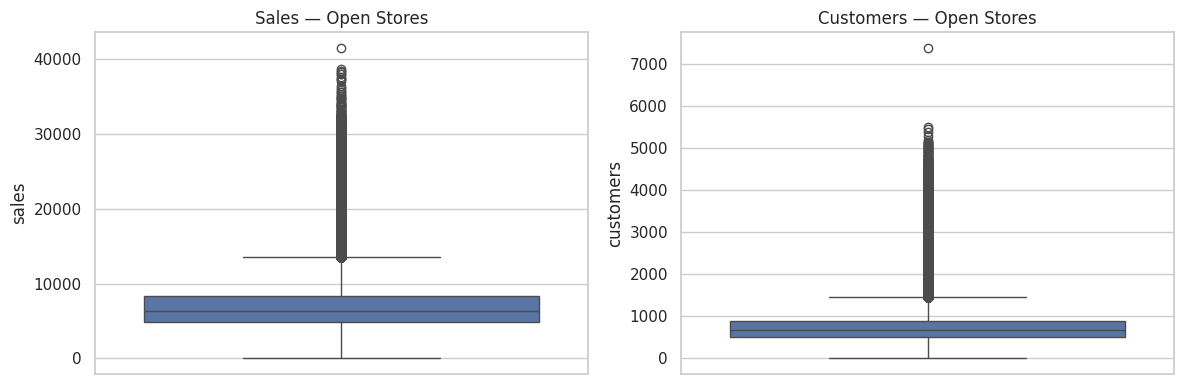

,store,date,sales,customers,promo
44393,909,2015-06-22,41551,1721,0
132946,262,2015-04-03,38722,5132,1
101726,262,2015-05-01,38484,5458,1
87231,262,2015-05-14,38367,5192,0
424086,57,2014-06-16,38037,1970,1
627776,817,2013-12-16,38025,4381,1
627220,261,2013-12-16,37646,1964,1
444361,262,2014-05-29,37403,5297,0
620531,262,2013-12-22,37376,4916,0
245945,262,2014-12-21,37122,4962,0


Treatment decision: IQR flags are retained, not deleted/capped automatically.
Reason: unusually high sales/customer counts may be genuine business activity.


In [ ]:
# Sales and Customers are assessed only for days when the store was open.
open_stores = train_clean.loc[train_clean["open"] == 1].copy()
outlier_rows = []

for column in ["sales", "customers"]:
    q1 = open_stores[column].quantile(0.25)
    q3 = open_stores[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((open_stores[column] < lower) | (open_stores[column] > upper)).sum())
    outlier_rows.append({
        "Column": column, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower Bound": lower, "Upper Bound": upper,
        "Outlier Count": count,
        "Outlier Percentage": count / len(open_stores) * 100
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=open_stores["sales"], ax=axes[0])
axes[0].set_title("Sales — Open Stores")
sns.boxplot(y=open_stores["customers"], ax=axes[1])
axes[1].set_title("Customers — Open Stores")
plt.tight_layout()
plt.show()

display(open_stores.nlargest(10, "sales")[["store", "date", "sales", "customers", "promo"]])

print("Treatment decision: IQR flags are retained, not deleted/capped automatically.")
print("Reason: unusually high sales/customer counts may be genuine business activity.")

In [ ]:
# Recheck core quality conditions after cleaning.
final_checks = {
    "Train missing cells": int(train_clean.isna().sum().sum()),
    "Test missing cells": int(test_clean.isna().sum().sum()),
    "Store missing cells": int(store_clean.isna().sum().sum()),
    "Train exact duplicates": int(train_clean.duplicated().sum()),
    "Test exact duplicates": int(test_clean.duplicated().sum()),
    "Store exact duplicates": int(store_clean.duplicated().sum()),
    "Invalid train dates": int(train_clean["date"].isna().sum()),
    "Invalid test dates": int(test_clean["date"].isna().sum()),
    "Test Open missing": int(test_clean["open"].isna().sum()),
    "Negative Sales": int((train_clean["sales"] < 0).sum()),
    "Negative Customers": int((train_clean["customers"] < 0).sum()),
    "Invalid train DayOfWeek": int((~train_clean["dayofweek"].between(1, 7)).sum()),
    "Invalid test DayOfWeek": int((~test_clean["dayofweek"].between(1, 7)).sum())
}
final_validation = pd.Series(final_checks, name="Count").to_frame()
display(final_validation)

# Key assertions: these should pass before exporting.
assert train_clean["date"].notna().all()
assert test_clean["date"].notna().all()
assert test_clean["open"].notna().all()
assert store_clean["store"].is_unique
assert test_clean["id"].is_unique
assert (train_clean["sales"] >= 0).all()
assert (train_clean["customers"] >= 0).all()
assert train_clean["dayofweek"].between(1, 7).all()
assert test_clean["dayofweek"].between(1, 7).all()

print("Core validation assertions passed.")

,Count
Train missing cells,0
Test missing cells,0
Store missing cells,0
Train exact duplicates,0
Test exact duplicates,0
Store exact duplicates,0
Invalid train dates,0
Invalid test dates,0
Test Open missing,0
Negative Sales,0


Core validation assertions passed.


In [ ]:
comparison = pd.DataFrame([
    {
        "Dataset": "Train",
        "Rows Before": len(train_raw), "Rows After": len(train_clean),
        "Columns Before": train_raw.shape[1], "Columns After": train_clean.shape[1],
        "Missing Before": int(train_raw.isna().sum().sum()),
        "Missing After": int(train_clean.isna().sum().sum()),
        "Exact Duplicates Before": int(train_raw.duplicated().sum()),
        "Exact Duplicates After": int(train_clean.duplicated().sum())
    },
    {
        "Dataset": "Test",
        "Rows Before": len(test_raw), "Rows After": len(test_clean),
        "Columns Before": test_raw.shape[1], "Columns After": test_clean.shape[1],
        "Missing Before": int(test_raw.isna().sum().sum()),
        "Missing After": int(test_clean.isna().sum().sum()),
        "Exact Duplicates Before": int(test_raw.duplicated().sum()),
        "Exact Duplicates After": int(test_clean.duplicated().sum())
    },
    {
        "Dataset": "Store",
        "Rows Before": len(store_raw), "Rows After": len(store_clean),
        "Columns Before": store_raw.shape[1], "Columns After": store_clean.shape[1],
        "Missing Before": int(store_raw.isna().sum().sum()),
        "Missing After": int(store_clean.isna().sum().sum()),
        "Exact Duplicates Before": int(store_raw.duplicated().sum()),
        "Exact Duplicates After": int(store_clean.duplicated().sum())
    }
])
display(comparison)

,Dataset,Rows Before,Rows After,Columns Before,Columns After,Missing Before,Missing After,Exact Duplicates Before,Exact Duplicates After
0,Train,1017209,1017209,9,9,0,0,0,0
1,Test,41088,41088,8,8,11,0,0,0
2,Store,1115,1115,10,13,2343,0,0,0


In [ ]:
os.makedirs("data/cleaned", exist_ok=True)

# Export cleaned datasets
train_clean.to_csv(
    "data/cleaned/cleaned_train.csv",
    index=False
)

test_clean.to_csv(
    "data/cleaned/cleaned_test.csv",
    index=False
)

store_clean.to_csv(
    "data/cleaned/cleaned_store.csv",
    index=False
)

print("All cleaned datasets exported successfully!")

# Verify exported files
for file in [
    "data/cleaned/cleaned_train.csv",
    "data/cleaned/cleaned_test.csv",
    "data/cleaned/cleaned_store.csv"
]:
    print(file, "Exists:", os.path.exists(file))

All cleaned datasets exported successfully!
data/cleaned/cleaned_train.csv Exists: True
data/cleaned/cleaned_test.csv Exists: True
data/cleaned/cleaned_store.csv Exists: True


In [ ]:
# Check exported CSV files
cleaned_train_check = pd.read_csv(
    "data/cleaned/cleaned_train.csv"
)
cleaned_test_check = pd.read_csv(
    "data/cleaned/cleaned_test.csv"
)
cleaned_store_check = pd.read_csv(
    "data/cleaned/cleaned_store.csv"
)
print("TRAIN:", cleaned_train_check.shape)
print("TEST:", cleaned_test_check.shape)
print("STORE:", cleaned_store_check.shape)
print("\nMissing Values:")
print("Train:", cleaned_train_check.isna().sum().sum())
print("Test:", cleaned_test_check.isna().sum().sum())
print("Store:", cleaned_store_check.isna().sum().sum())

TRAIN: (1017209, 9)
TEST: (41088, 8)
STORE: (1115, 13)

Missing Values:
Train: 0
Test: 0
Store: 0


In [ ]:
os.makedirs("data/processed", exist_ok=True)
train_clean.to_csv("data/cleaned/cleaned_train.csv", index=False)
test_clean.to_csv("data/cleaned/cleaned_test.csv", index=False)
store_clean.to_csv("data/cleaned/cleaned_store.csv", index=False)

print("All 3 CSV files exported successfully!")

All 3 CSV files exported successfully!


In [ ]:
from google.colab import files

files.download("data/cleaned/cleaned_train.csv")
files.download("data/cleaned/cleaned_test.csv")
files.download("data/cleaned/cleaned_store.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("TASK 1 — DATA CLEANING COMPLETION CHECKLIST")
checklist = {
    "Datasets loaded and profiled": True,
    "Missing values identified and treated/documented": True,
    "Exact duplicates checked and handled": True,
    "Column names standardized": True,
    "Data types standardized where appropriate": True,
    "Business rules validated": True,
    "Outliers detected and treatment decision documented": True,
    "Categorical values standardized; encoding deferred to model pipeline": True,
    "Cleaned CSV files exported": True,
    "Cleaning and validation reports exported": True
}
for item, done in checklist.items():
    print(("✓" if done else "✗"), item)

print("\nTask 1 notebook execution completed. Review all validation outputs before submission.")

TASK 1 — DATA CLEANING COMPLETION CHECKLIST
✓ Datasets loaded and profiled
✓ Missing values identified and treated/documented
✓ Exact duplicates checked and handled
✓ Column names standardized
✓ Data types standardized where appropriate
✓ Business rules validated
✓ Outliers detected and treatment decision documented
✓ Categorical values standardized; encoding deferred to model pipeline
✓ Cleaned CSV files exported
✓ Cleaning and validation reports exported

Task 1 notebook execution completed. Review all validation outputs before submission.
